# Punto 3 (0.6) — YCbCr: negativo de la log sobre Cr

Aplique la transformación a su imagen RGB.

- Paso 1. Convierta su imagen RGB a formato YCbCr
- Paso 2. Aplique el negativo al resultado de una transformación logarítmica sobre el componente Cr
- Paso 3. Reconstruya la imagen en YCbCr con el componente Cr modificado en el paso 2 y los demás componentes sin modificar
- Paso 4. Convierta la imagen obtenida en el Paso 3 al espacio RGB

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from skimage.color import rgb2ycbcr, ycbcr2rgb


## Imagen original RGB

(1024, 1024, 3) uint8


(np.float64(-0.5), np.float64(1023.5), np.float64(1023.5), np.float64(-0.5))

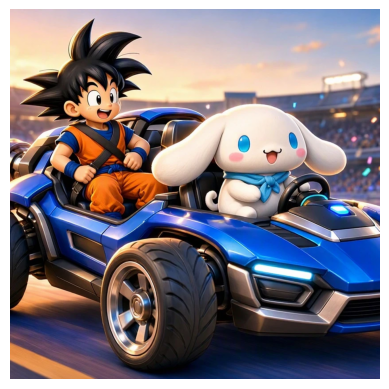

In [2]:
img = np.array(Image.open("../images/mi_imagen.png").convert("RGB"))
print(img.shape, img.dtype)

plt.figure()
plt.imshow(img)
plt.axis("off")


## Paso 1 — RGB a YCbCr

In [3]:
ycbcr = rgb2ycbcr(img)
print(ycbcr.min(axis=(0, 1)).round(1), ycbcr.max(axis=(0, 1)).round(1))


[16.  54.9 30.1] [235.  212.7 200.3]


## Paso 2 — Negativo de la log sobre Cr

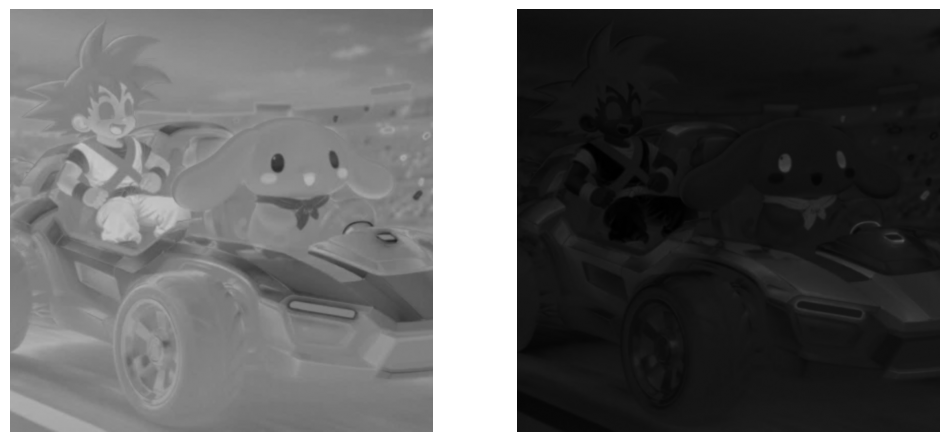

In [4]:
cr = np.round(ycbcr[..., 2]).astype(np.uint8)

cr_log = np.zeros_like(cr)
cv2.intensity_transform.logTransform(cr, cr_log)
cr_mod = cv2.bitwise_not(cr_log)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cr, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cr_mod, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.savefig("../results/punto3_cr.png", bbox_inches="tight", pad_inches=0)


## Pasos 3 y 4 — Reconstrucción y vuelta a RGB

In [5]:
ycbcr_mod = ycbcr.copy()
ycbcr_mod[..., 2] = cr_mod
resultado = np.clip(np.round(ycbcr2rgb(ycbcr_mod) * 255), 0, 255).astype(np.uint8)

Image.fromarray(resultado).save("../results/punto3_transformada.png")


## Comparación original vs transformada

Complete la tabla con la imagen original RGB y la imagen transformada.

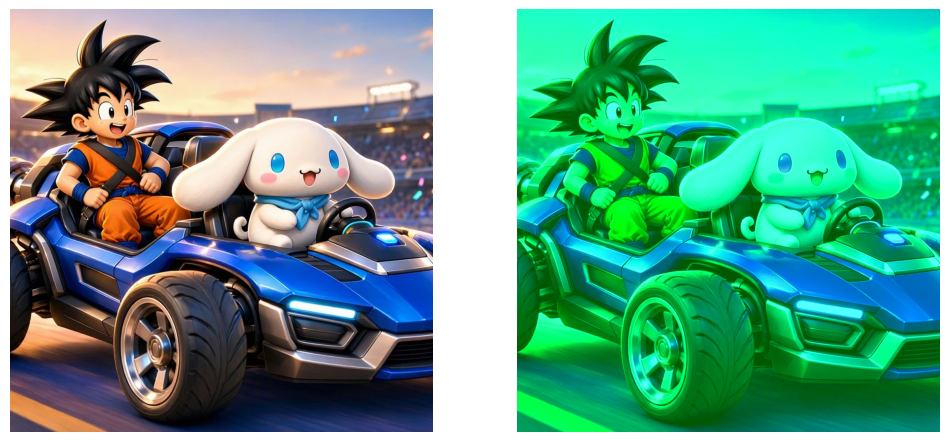

In [6]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(resultado)
plt.axis("off")
plt.savefig("../results/punto3_comparacion.png", bbox_inches="tight", pad_inches=0)
